# 02 – Random Forest
Same data, preprocessing, CV folds and search budget as the XGBoost notebook, so the two can be compared fairly.

In [1]:
import warnings, json, joblib; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score, RandomizedSearchCV
from common import *
pre = joblib.load(MODELS/"preprocessor.pkl")
(Xtr,ytr),(Xva,yva),(Xte,yte) = load_split("train"),load_split("val"),load_split("test")
Atr,Ava,Ate = pre.transform(Xtr),pre.transform(Xva),pre.transform(Xte)
cv = KFold(3, shuffle=True, random_state=SEED)

## Untuned baseline (cross-validated)

In [2]:
s = cross_val_score(RandomForestRegressor(n_estimators=300,n_jobs=-1,random_state=SEED), Atr, ytr, cv=cv, scoring="neg_root_mean_squared_error")
base_cv = float(-s.mean()); print(f"Default RF – CV RMSE (log price): {base_cv:.4f} ± {s.std():.4f}")

Default RF – CV RMSE (log price): 0.2272 ± 0.0120


## Hyper-parameter search (12 random candidates, 3-fold CV)

In [3]:
space = {"n_estimators":[200,300],"max_depth":[None,20,30],"min_samples_leaf":[1,2,3,5],"max_features":[0.2,0.3,0.4,0.6,1.0]}
search = RandomizedSearchCV(RandomForestRegressor(n_jobs=-1,random_state=SEED), space, n_iter=12, cv=cv,
                            scoring="neg_root_mean_squared_error", random_state=SEED).fit(Atr,ytr)
rf = search.best_estimator_
print("best params:", search.best_params_); print("tuned CV RMSE (log):", round(-search.best_score_,4))
pd.DataFrame(search.cv_results_)[["params","mean_test_score","rank_test_score"]].sort_values("rank_test_score").head(5)

best params: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.2, 'max_depth': 20}
tuned CV RMSE (log): 0.2215


,params,mean_test_score,rank_test_score
8,"{'n_estimators': 200, 'min_samples_leaf': 1, '...",-0.221523,1
5,"{'n_estimators': 200, 'min_samples_leaf': 1, '...",-0.223933,2
10,"{'n_estimators': 200, 'min_samples_leaf': 2, '...",-0.224378,3
7,"{'n_estimators': 200, 'min_samples_leaf': 2, '...",-0.224640,4
9,"{'n_estimators': 300, 'min_samples_leaf': 2, '...",-0.224960,5


## Test-set evaluation and saving

In [4]:
pred_test = rf.predict(Ate); m = evaluate(yte,pred_test)
print({k:round(v,3) for k,v in m.items()})
joblib.dump(rf, MODELS/"random_forest.pkl", compress=3)
json.dump({"model":"Random Forest","best_params":search.best_params_,"cv_rmse_log_default":base_cv,
           "cv_rmse_log_tuned":float(-search.best_score_),"test":m}, open(RESULTS/"rf_results.json","w"), indent=1, default=str)

{'MAE': 6.394, 'MSE': 578.199, 'RMSE': 24.046, 'R2': 0.761}


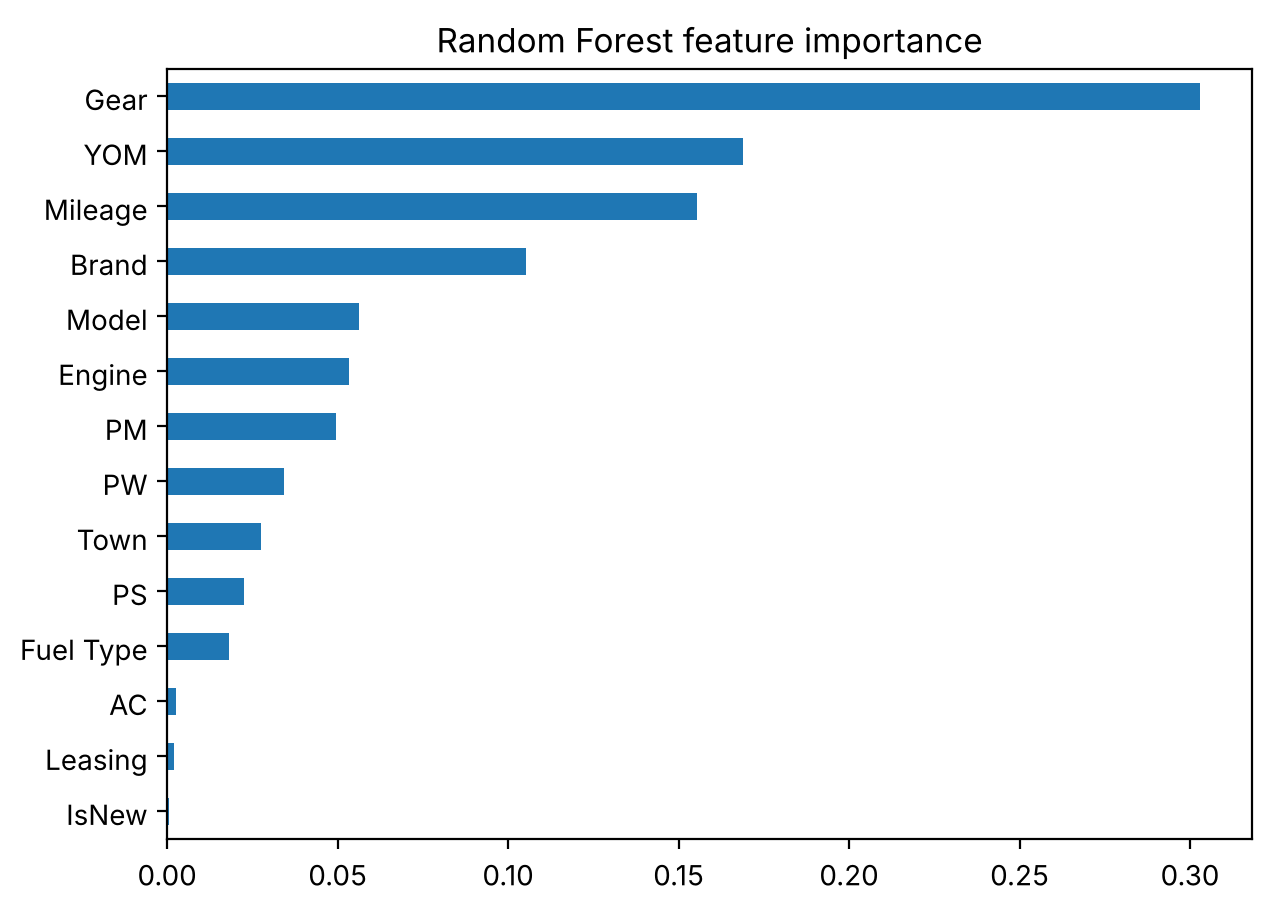

In [5]:
fn = pre.get_feature_names_out()
def agg(imp):
    out = {}
    for n,v in zip(fn,imp):
        b = n.split("__",1)[1]
        for c in CAT:
            if b.startswith(c+"_"): b = c; break
        out[b] = out.get(b,0)+v
    return pd.Series(out).sort_values(ascending=False)
fi = agg(rf.feature_importances_); fi.plot.barh(figsize=(7,5)).invert_yaxis(); plt.title("Random Forest feature importance"); plt.show()